# 03 · Feature selection: which questions matter?

The bonus questions:

1. Which questions are most important for predicting happiness?
2. What is the **smallest set of questions** that keeps (or improves) predictive power?
3. Can any question be **removed** from the next survey?

We look through three lenses, from simplest to most rigorous, and only trust conclusions they
agree on:

| Lens | Question it answers |
|---|---|
| Univariate tests | Is each question, on its own, related to happiness? |
| Permutation importance | How much does a model's accuracy on *new* customers drop if one question's answers are scrambled? |
| Subset search (all 63 combinations) | Which combination predicts best, and what is the smallest one that's as good? |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, MultipleLocator, PercentFormatter
from scipy.stats import mannwhitneyu
from sklearn.model_selection import cross_val_score

from happiness.config import CV_SPLITS, FEATURES, FIGURES_DIR, QUESTIONS, TARGET
from happiness.data import load_data
from happiness.evaluation import corrected_ttest, repeated_cv, tuned
from happiness.feature_selection import (
    nested_subset_selection,
    permutation_importance_cv,
    score_subsets,
    selection_frequency,
    selection_models,
)
from happiness.models import get_candidates

BLUE, LIGHT_BLUE, ORANGE = "#2a78d6", "#b7d3f6", "#eb6834"
INK, MUTED = "#0b0b0b", "#52514e"
SELECTION_NAMES = {
    "decision_tree": "Decision tree (depth 2, 1–5 scale)",
    "logistic_regression": "Logistic regression (top-box)",
}

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "axes.axisbelow": True,
    }
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = load_data()
X, y = df[FEATURES], df[TARGET]
baseline_accuracy = y.value_counts(normalize=True).max()


def question_labels(features):
    return [f"{f} · {QUESTIONS[f]}" for f in features]


def grouped_barh(ax, frame, colors, value_format=None):
    """One horizontal bar per question and column of `frame`, optionally labelled."""
    rows = np.arange(len(frame))
    height = 0.8 / frame.shape[1]
    for i, (column, color) in enumerate(zip(frame.columns, colors, strict=False)):
        offset = (i - (frame.shape[1] - 1) / 2) * height
        bars = ax.barh(
            rows + offset,
            frame[column],
            height=height,
            color=color,
            label=column,
            edgecolor="white",
            linewidth=1,
        )
        if value_format:
            ax.bar_label(
                bars,
                labels=[value_format.format(v) for v in frame[column]],
                padding=3,
                fontsize=8,
                color=MUTED,
            )
    ax.set_yticks(rows, question_labels(frame.index))
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=frame.shape[1], frameon=False)

## 1. Univariate view (recap from the EDA)

Each question on its own: rank correlation with happiness, and the Mann–Whitney p-value for
"do happy and unhappy customers answer differently?".

In [2]:
univariate = pd.DataFrame(
    {
        "question": [QUESTIONS[f] for f in FEATURES],
        "spearman_r": X.corrwith(y, method="spearman"),
        "mann_whitney_p": [
            mannwhitneyu(X.loc[y == 1, f], X.loc[y == 0, f]).pvalue for f in FEATURES
        ],
    },
    index=FEATURES,
)
univariate.round(3)

,question,spearman_r,mann_whitney_p
X1,My order was delivered on time,0.291,0.001
X2,Contents of my order was as I expected,-0.034,0.703
X3,I ordered everything I wanted to order,0.162,0.070
X4,I paid a good price for my order,0.081,0.364
X5,I am satisfied with my courier,0.227,0.011
X6,The app makes ordering easy for me,0.174,0.052


On its own, X1 is clearly related to happiness (p = 0.001), and so is X5 (p = 0.011). But
questions are correlated with each other (X1–X6 r = 0.51, X1–X5 r = 0.42), so a question can look
useful alone while carrying information another question already provides. The next two
lenses look at questions *together*.

## 2. Permutation importance on held-out customers

For each of the 50 outer folds: fit a model on the training customers, then shuffle one
question's answers among the *test* customers and measure how much accuracy drops. A large
drop means the model relies on that question to predict new customers. A drop near zero (or
negative) means the question only adds noise.

We use two different model families, so the conclusion doesn't depend on one model's quirks.

In [3]:
candidates = get_candidates()
importance_models = {
    "Random forest (top-box)": tuned(candidates["random_forest"], "top_box"),
    "Logistic regression (1–5 scale)": tuned(candidates["logistic_regression"], "ordinal"),
}
importance = {
    name: permutation_importance_cv(model, X, y) for name, model in importance_models.items()
}
importance_mean = pd.DataFrame({name: imp.mean() for name, imp in importance.items()})
importance_mean.round(3)

,Random forest (top-box),Logistic regression (1–5 scale)
X1,0.101,0.029
X2,0.000,-0.005
X3,0.000,-0.006
X4,-0.007,-0.004
X5,-0.003,-0.001
X6,-0.003,0.005


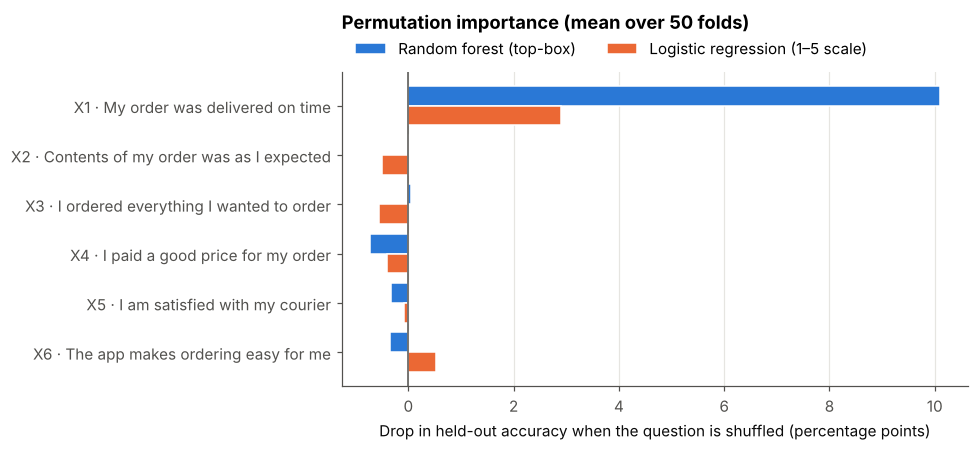

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
grouped_barh(ax, importance_mean, [BLUE, ORANGE])
ax.axvline(0, color=MUTED, linewidth=1)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v * 100:.0f}"))
ax.set_xlabel("Drop in held-out accuracy when the question is shuffled (percentage points)")
ax.set_title("Permutation importance (mean over 50 folds)", loc="left", pad=28)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "permutation_importance.png", bbox_inches="tight")
plt.show()

Both models agree: **X1 is the only question whose loss hurts predictions** for new
customers. Scrambling any other question changes accuracy by less than 1 point, sometimes
improving it, which means those answers add noise rather than signal once X1 is known.

## 3. Exhaustive search over all 63 combinations of questions

With 6 questions there are only 2⁶ − 1 = 63 non-empty subsets, so we can score every one
rather than rely on a greedy heuristic. Each subset is scored with the same 50-fold repeated CV,
using a **shallow decision tree** (depth 2, at least 5 customers per leaf). It can express
rules like "X1 = 5" and one follow-up question, and its settings are fixed so the search
chooses only the questions.

To pick the minimal set we use the **one-standard-error rule**: take the subset with the fewest
questions whose accuracy is within one standard error of the best. Differences smaller than
that are indistinguishable from noise, so we prefer the simpler survey.

In [5]:
tree, tree_encoding = selection_models()["decision_tree"]
subsets, search = score_subsets(tree, X, y, encoding=tree_encoding)

best = subsets.iloc[0]
threshold = best.accuracy_mean - best.accuracy_std / np.sqrt(CV_SPLITS)
chosen = "+".join(search.best_params_["select__columns"])
print(f"Best subset: {best.questions} ({best.accuracy_mean:.1%})")
print(f"Within one standard error: accuracy >= {threshold:.1%}")
print(f"Smallest subset within one standard error: {chosen}")
subsets.head(10).round(3)

Best subset: X1+X5 (67.3%)
Within one standard error: accuracy >= 63.8%
Smallest subset within one standard error: X1


,questions,n_questions,accuracy_mean,accuracy_std
0,X1+X5,2,0.673,0.080
1,X1+X2+X5,3,0.673,0.080
2,X1+X4+X5,3,0.663,0.082
3,X1+X2+X4+X5,4,0.663,0.082
4,X1,1,0.651,0.074
5,X1+X2,2,0.651,0.074
6,X1+X4,2,0.646,0.078
7,X1+X2+X4,3,0.646,0.078
8,X1+X5+X6,3,0.645,0.075
9,X1+X2+X5+X6,4,0.643,0.077


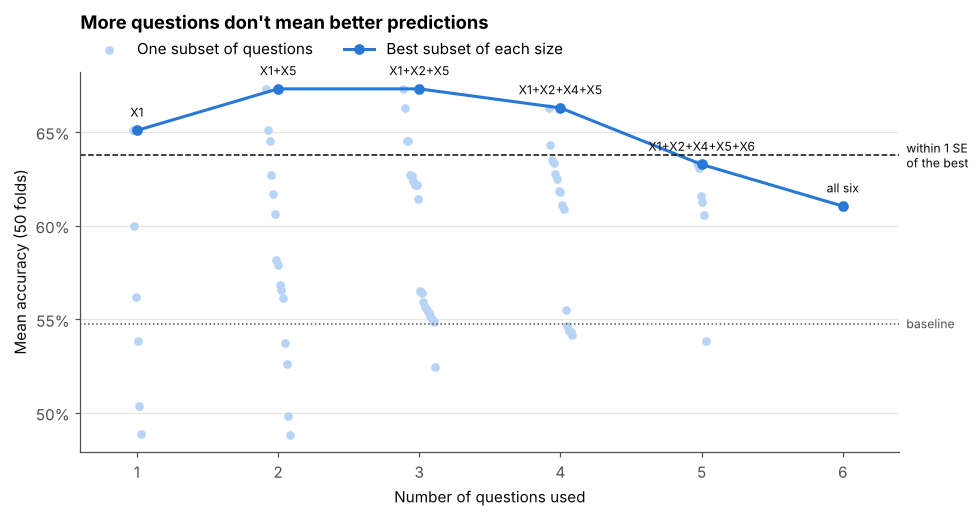

In [6]:
best_per_size = subsets.loc[subsets.groupby("n_questions")["accuracy_mean"].idxmax()]
spread = subsets.groupby("n_questions").cumcount()
jitter = (spread - spread.groupby(subsets["n_questions"]).transform("mean")) * 0.012

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.scatter(
    subsets.n_questions + jitter,
    subsets.accuracy_mean,
    s=22,
    color=LIGHT_BLUE,
    label="One subset of questions",
)
ax.plot(
    best_per_size.n_questions,
    best_per_size.accuracy_mean,
    color=BLUE,
    marker="o",
    linewidth=2,
    label="Best subset of each size",
)
for _, row in best_per_size.iterrows():
    text = "all six" if row.n_questions == len(FEATURES) else row.questions
    ax.annotate(
        text,
        (row.n_questions, row.accuracy_mean),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color=INK,
    )
ax.axhline(threshold, color=INK, linestyle="--", linewidth=1)
ax.text(6.45, threshold, "within 1 SE\nof the best", va="center", fontsize=8, color=INK)
ax.axhline(baseline_accuracy, color=MUTED, linestyle=":", linewidth=1)
ax.text(6.45, baseline_accuracy, "baseline", va="center", fontsize=8, color=MUTED)
ax.set_xlim(0.6, 6.4)
ax.set_xticks(range(1, len(FEATURES) + 1))
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Number of questions used")
ax.set_ylabel("Mean accuracy (50 folds)")
ax.set_title("More questions don't mean better predictions", loc="left", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "subset_search.png", bbox_inches="tight")
plt.show()

- Accuracy **peaks with two questions (X1 + X5)**. The best three-question subset only ties
  it, because the depth-2 tree ignores the extra question. From there accuracy falls steadily:
  with all six, the same model is about 6 points worse than its best. Every extra question gives
  the tree another way to fit noise.
- **Every top subset contains X1.** X1 alone is within one standard error of the best, so the
  one-standard-error rule picks **X1 on its own**.

Is X1 + X5 really better than X1 alone, and is X1 alone really better than all six? Both are
scored on the same folds, so we can use the corrected t-test from the modeling notebook.

In [7]:
fold_accuracy = {
    name: cross_val_score(
        tree.pipeline(tree_encoding, columns=tuple(name.split("+"))),
        X,
        y,
        cv=repeated_cv(),
        n_jobs=-1,
    )
    for name in ["X1", "X1+X5", "+".join(FEATURES)]
}
rows = []
for a, b in [("X1+X5", "X1"), ("X1", "+".join(FEATURES))]:
    diff, p_value = corrected_ttest(fold_accuracy[a], fold_accuracy[b])
    rows.append({"comparison": f"{a} vs {b}", "accuracy gain": diff, "p-value": p_value})
pd.DataFrame(rows).set_index("comparison").round(3)

,accuracy gain,p-value
comparison,,
X1+X5 vs X1,0.022,0.380
X1 vs X1+X2+X3+X4+X5+X6,0.040,0.336


- Adding X5 to X1 gains about 2 points, but that is **not statistically significant**. It
  could easily be noise.
- Dropping five questions (all six → X1) *gains* about 4 points with this model. The direction
  is clear, but the corrected test also can't call this gap significant.
- The honest reading: **X1 carries essentially all of the predictive information**, and the
  other questions add nothing measurable on top of it.

## 4. Honest estimate: choosing questions inside cross-validation

Picking the best of 63 subsets on the same folds we report is optimistic: we'd be selecting
the subset that got lucky on those folds. So we nest the whole procedure. In each of the 50
outer folds, the subset search (with the one-standard-error rule) runs on the training
customers only. The outer test fold scores the result. This gives:

- an **unbiased accuracy** for "choose questions, then train", and
- **selection stability**: how often each question is chosen across 50 different training sets.

We run it for two different selection models.

In [8]:
nested = {
    name: nested_subset_selection(candidate, X, y, encoding=encoding)
    for name, (candidate, encoding) in selection_models().items()
}
pd.DataFrame(
    {
        SELECTION_NAMES[name]: {
            "nested accuracy": f"{s.accuracy.mean():.1%} ± {s.accuracy.std():.1%}",
            "most chosen subset": s.questions.mode()[0],
            "chosen in share of folds": f"{(s.questions == s.questions.mode()[0]).mean():.0%}",
        }
        for name, s in nested.items()
    }
)

,"Decision tree (depth 2, 1–5 scale)",Logistic regression (top-box)
nested accuracy,63.2% ± 7.6%,65.1% ± 7.5%
most chosen subset,X1,X1
chosen in share of folds,78%,100%


In [9]:
nested["decision_tree"]["questions"].value_counts().rename("folds (decision tree)")

questions
X1       39
X1+X5     5
X6        5
X1+X6     1
Name: folds (decision tree), dtype: int64

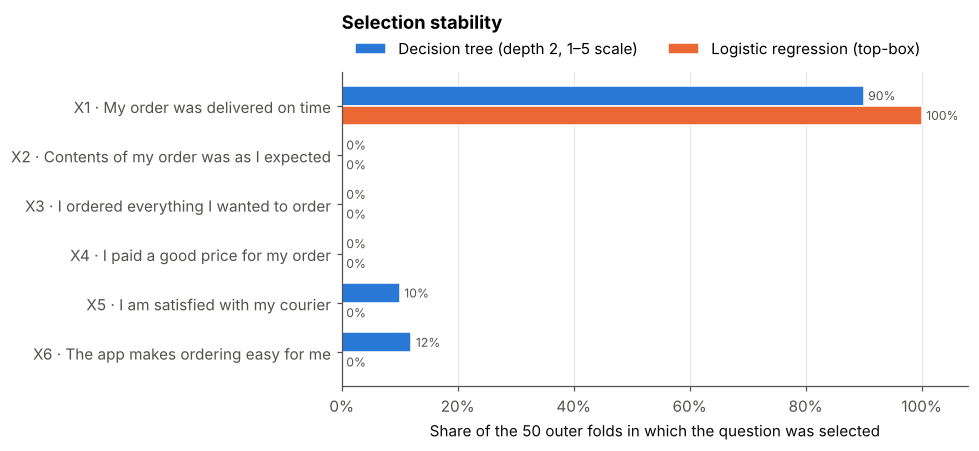

In [10]:
frequency = pd.DataFrame(
    {SELECTION_NAMES[name]: selection_frequency(s.questions) for name, s in nested.items()}
)

fig, ax = plt.subplots(figsize=(9, 4.2))
grouped_barh(ax, frequency, [BLUE, ORANGE], value_format="{:.0%}")
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Share of the 50 outer folds in which the question was selected")
ax.set_title("Selection stability", loc="left", pad=28)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "selection_frequency.png", bbox_inches="tight")
plt.show()

- **X1 is selected almost every time** by both models.
- **X2, X3 and X4 are never selected.**
- X5 and X6 are picked occasionally (by the tree only). In the folds where X1 is missing, X6
  replaces it: the two are correlated (r = 0.51), so X6 acts as a weaker proxy for the same thing.
- The honest accuracy of the full "choose questions, then train" procedure is about 63–65%. That
  matches the modeling notebook's best result, which used all six questions and let the tree
  ignore most of them.

## 5. Consensus

In [11]:
consensus = pd.concat(
    [
        univariate[["question", "mann_whitney_p"]],
        importance_mean.add_prefix("importance: "),
        frequency.add_prefix("selected: "),
    ],
    axis=1,
)
consensus.round(3)

,question,mann_whitney_p,importance: Random forest (top-box),importance: Logistic regression (1–5 scale),"selected: Decision tree (depth 2, 1–5 scale)",selected: Logistic regression (top-box)
X1,My order was delivered on time,0.001,0.101,0.029,0.90,1.0
X2,Contents of my order was as I expected,0.703,0.000,-0.005,0.00,0.0
X3,I ordered everything I wanted to order,0.070,0.000,-0.006,0.00,0.0
X4,I paid a good price for my order,0.364,-0.007,-0.004,0.00,0.0
X5,I am satisfied with my courier,0.011,-0.003,-0.001,0.10,0.0
X6,The app makes ordering easy for me,0.052,-0.003,0.005,0.12,0.0


| Question | Evidence | Recommendation |
|---|---|---|
| **X1** · delivered on time | strongest in every lens; selected in ~all folds | **keep (essential)** |
| **X5** · satisfied with courier | related on its own; part of the best 2-question subset, but no significant gain on top of X1 | **keep (optional)**: cheap to ask and points to an actionable lever |
| **X6** · app makes ordering easy | moderate on its own, but overlaps with X1 and adds nothing on top | can be removed for prediction |
| **X3** · ordered everything I wanted | weak on its own, never selected | **remove** |
| **X4** · paid a good price | no relationship, never selected | **remove** |
| **X2** · contents as expected | no relationship, never selected | **remove** (or reword: "as expected" is ambiguous) |

### Answers to the bonus questions

- **Most important question:** X1, *"my order was delivered on time"*. Specifically, whether
  the customer answered **5**.
- **Minimal set:** **{X1}**. It keeps all the measurable predictive power, and even *improves*
  accuracy compared with using all six questions (≈65% vs ≈61% for the same model). Adding X5
  gives the best observed subset (≈67%), but the gain is within noise.
- **Questions we can remove:** **X2, X3 and X4** with no loss. X6 can go too if the survey
  is only for prediction.

### What this means for the next survey

The ceiling here comes from the *survey*, not the model: 17 customers gave identical answers
to someone with the opposite outcome. Shortening the survey to X1 + X5 frees room for questions
that might explain the rest of the variation: for example, how late the order was, whether
support resolved a problem, or the condition of the delivered items.